# Pretrained ResNet features -> clustering

A **reference point** for the unsupervised representations: no training at all, just an ImageNet-pretrained ResNet as a frozen feature extractor.

1. embed `N_PAINTINGS` paintings with the ResNet (global-average-pooled output of the last conv stage);
2. PCA (whitened) -> L2 normalise;
3. cluster with **K-means**, **DBSCAN** or **HDBSCAN** (`METHOD`);
4. compare the clusters with the metadata (silhouette, NMI / AMI / ARI), exactly like the other notebooks.

Note: the ResNet was trained with ImageNet **labels**, so this is not an unsupervised method; it shows how far off-the-shelf features get.

All parameters are in the **Config** cell. Features are cached to disk, so changing only the clustering part does not re-run the ResNet.

In [12]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import umap
from IPython.display import display
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from torch.utils.data import DataLoader, Subset
from torchvision.transforms import v2
from tqdm.auto import tqdm

if "google.colab" in sys.modules:
    SRC = Path("/content/Project/src")          # or /content/drive/MyDrive/.../Project/src
else:
    SRC = Path.cwd().parents[1]                 # training/ -> restore_pipeline/ -> src/

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from restore_pipeline.dataprocessing.dataloading import DataConfig, get_splits, get_splits_dataloaders
from restore_pipeline.clustering.plotting import plot_cluster_samples, plot_clusters_2d, plot_kmeans_sweep, umap_project
from restore_pipeline.clustering.utils import kmeans_sweep

# Config

In [13]:
# ---------------- Data ----------------
DATA_DIR    = Path("../data")
IMG_SIZE    = 224                 # ResNet's training resolution. 128 is faster but the features get worse
BATCH_SIZE  = 64
NUM_WORKERS = 2
SEED        = 42

SPLIT         = "train"           # "train" | "val" | "test"
N_PAINTINGS   = 10_000            # None = whole split
LABEL_COLUMNS = ["style", "genre", "artist"]

# ---------------- Feature extractor ----------------
BACKBONE  = "resnet50"            # "resnet18" (512-d) | "resnet34" (512-d) | "resnet50" (2048-d) | "resnet101" (2048-d)
CACHE_DIR = Path("features")      # extracted features are saved here and reused. None = no cache

# ---------------- Clustering ----------------
METHOD  = "dbscan"                # "kmeans" | "dbscan" | "hdbscan"
PCA_DIM = 64                      # PCA (whitened) before L2 normalisation. None = no PCA

# K-means
K_SWEEP = range(2, 101, 10)
K       = 42

# DBSCAN / HDBSCAN. Density is meaningless in high dimensions, so they run in a low-dim UMAP space (None = in the PCA features)
DENSITY_UMAP_DIM = 10
MIN_SAMPLES      = 10             # neighbours needed to be a core point
DBSCAN_EPS       = None           # None = EPS_QUANTILE of the k-distance curve (plotted below)
EPS_QUANTILE     = 0.5
HDBSCAN_MIN_CLUSTER_SIZE = 50     # smallest group HDBSCAN accepts as a cluster

device = "cuda" if torch.cuda.is_available() else "cpu"
assert METHOD in ("kmeans", "dbscan", "hdbscan"), METHOD
RUN_NAME = f"{BACKBONE} (ImageNet), {METHOD}"

# Data

Images are normalised with the ImageNet mean / std the ResNet was trained with. The sample grids use the raw rows, so they are unaffected.

In [14]:
WEIGHTS = torchvision.models.get_model_weights(BACKBONE).DEFAULT
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

TRANSFORM = v2.Compose([
    v2.ToImage(),
    v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),     # whole painting squashed, no centre crop (a crop cuts off the composition)
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

data_cfg = DataConfig(
    processed_path=DATA_DIR / "wikiart_train_processed",
    cache_dir=str(DATA_DIR),
    seed=SEED,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle_train=False,
    transform_train=TRANSFORM,
    transform_val=TRANSFORM,
    transform_test=TRANSFORM,
    transform_full=TRANSFORM,
)
splits = dict(zip(["train", "val", "test"], get_splits(data_cfg)))                    # raw rows: images + metadata
image_datasets = {name: loader.dataset                                                # transformed images only
                  for name, loader in zip(["train", "val", "test"], get_splits_dataloaders(data_cfg))}


def sample_indices(n_total: int, n: int | None) -> np.ndarray:
    """`n` random row indices, sorted (rows keep dataset order). All rows if `n` is None."""
    if n is None or n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.default_rng(SEED).choice(n_total, size=n, replace=False))


cluster_idx = sample_indices(len(image_datasets[SPLIT]), N_PAINTINGS)
cluster_loader = DataLoader(
    Subset(image_datasets[SPLIT], cluster_idx.tolist()),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False,
)

# Row i of embed / features / labels / meta is painting cluster_idx[i]
ds_cluster = splits[SPLIT].select(cluster_idx)
meta = ds_cluster.select_columns(LABEL_COLUMNS).to_pandas()
print(f"{SPLIT}: {len(cluster_idx)} paintings ({len(cluster_loader)} batches)")

train: 10000 paintings (157 batches)


# Feature extraction

The classification layer (`fc`) is replaced by an identity, so the output is the pooled feature vector. Runs under fp16 autocast for speed; features are stored as float32.

In [15]:
@torch.inference_mode()
def extract_features(model: torch.nn.Module, loader: DataLoader) -> np.ndarray:
    model.eval()
    out = []
    for batch in tqdm(loader, desc="features"):
        x = batch["image"].to(device, non_blocking=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
            out.append(model(x).float().cpu())
    return torch.cat(out).numpy()


cache = None if CACHE_DIR is None else CACHE_DIR / f"{BACKBONE}_{SPLIT}_{N_PAINTINGS}_{IMG_SIZE}px_seed{SEED}.npy"

if cache is not None and cache.exists():
    embed = np.load(cache)
    print(f"loaded {cache}")
else:
    resnet = torchvision.models.get_model(BACKBONE, weights=WEIGHTS)
    resnet.fc = torch.nn.Identity()
    resnet = resnet.to(device)
    embed = extract_features(resnet, cluster_loader)
    del resnet
    torch.cuda.empty_cache()
    if cache is not None:
        cache.parent.mkdir(parents=True, exist_ok=True)
        np.save(cache, embed)
        print(f"saved {cache}")

assert len(embed) == len(meta), "embeddings and metadata are not aligned"
print(f"embedding: {embed.shape}")

loaded features\resnet50_train_10000_224px_seed42.npy
embedding: (10000, 2048)


# Preprocessing

In [16]:
steps = [PCA(PCA_DIM, whiten=True, random_state=SEED)] if PCA_DIM is not None else []
preprocess = make_pipeline(*steps, Normalizer(norm="l2"))
features = preprocess.fit_transform(embed)

if PCA_DIM is not None:
    explained = preprocess.steps[0][1].explained_variance_ratio_.sum()
    print(f"PCA {embed.shape[1]} -> {PCA_DIM}: {explained:.1%} of the variance kept")
print(f"features: {features.shape}")

PCA 2048 -> 64: 58.3% of the variance kept
features: (10000, 64)


# Clustering

* **K-means**: sweep over `K_SWEEP` (inertia + silhouette), then the final model with `K`.
* **DBSCAN / HDBSCAN**: run in a `DENSITY_UMAP_DIM`-dimensional UMAP space (in 64+ dimensions all distances look alike, so "density" means little). They choose the number of clusters themselves and label outliers `-1` (**noise**).
  For DBSCAN, the k-distance plot shows how far each painting's `MIN_SAMPLES`-th neighbour is; a good `eps` sits near the bend of the curve.

In [ ]:
if METHOD == "kmeans":
    sweep = kmeans_sweep(features, K_SWEEP, seed=SEED)
    plot_kmeans_sweep(sweep, title=f"{RUN_NAME}, {SPLIT} ({len(features)} paintings)")
    plt.show()
    cluster_space = features
else:
    if DENSITY_UMAP_DIM is not None:
        cluster_space = umap.UMAP(n_components=DENSITY_UMAP_DIM, n_neighbors=30, min_dist=0.0,
                                  random_state=SEED).fit_transform(features)
    else:
        cluster_space = features
    print(f"density clustering in {cluster_space.shape[1]} dims")

    if METHOD == "dbscan":
        distances, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(cluster_space).kneighbors(cluster_space)
        k_dist = np.sort(distances[:, -1])
        eps = DBSCAN_EPS if DBSCAN_EPS is not None else float(np.quantile(k_dist, EPS_QUANTILE))
        plt.plot(k_dist)
        plt.axhline(eps, color="red", linestyle="--", label=f"eps = {eps:.3f}")
        plt.title(f"k-distance ({MIN_SAMPLES}-th neighbour), sorted")
        plt.xlabel("paintings")
        plt.ylabel("distance")
        plt.legend()
        plt.show()

c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [ ]:
if METHOD == "kmeans":
    clusterer = KMeans(n_clusters=K, n_init=10, random_state=SEED)
elif METHOD == "dbscan":
    clusterer = DBSCAN(eps=eps, min_samples=MIN_SAMPLES)
else:
    clusterer = HDBSCAN(min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)

labels = clusterer.fit_predict(cluster_space)
noise = labels == -1
n_clusters = len(np.unique(labels[~noise]))

print(f"{n_clusters} clusters, noise: {noise.sum()} paintings ({noise.mean():.1%})")
print("cluster sizes (largest first):", np.sort(np.bincount(labels[~noise]))[::-1][:20])

c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


2 clusters, noise: 0 paintings (0.0%)
cluster sizes (largest first): [9849  151]


c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


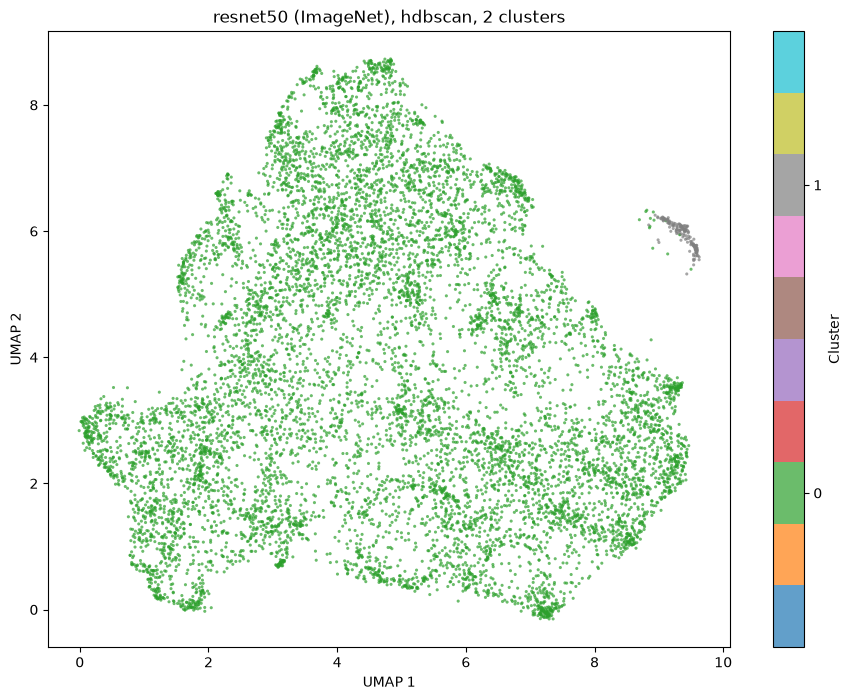

In [ ]:
embedding_2d, idx_2d = umap_project(features, seed=SEED)
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"{RUN_NAME}, {n_clusters} clusters")
plt.show()

# Evaluation

Noise points (`-1`) are left out of the silhouette and of NMI / AMI / ARI: the scores describe the paintings that **were** clustered, and the `clustered` / `noise` columns say how many that is.
A method can look good by calling most paintings noise, so always read the metrics together with the noise share.

The silhouette is computed in the space the clustering ran in (PCA features for K-means, UMAP space for DBSCAN / HDBSCAN), so it is not comparable across methods; NMI / AMI / ARI are.

In [ ]:
if n_clusters >= 2:
    kept = ~noise
    silhouette = silhouette_score(cluster_space[kept], labels[kept],
                                  sample_size=min(10_000, int(kept.sum())), random_state=SEED)
    print(f"Silhouette = {silhouette:.3f} on {kept.sum()} clustered paintings ({n_clusters} clusters)")
else:
    print("fewer than 2 clusters: silhouette undefined (change eps / min_cluster_size)")

rows = []
for column in LABEL_COLUMNS:
    known = meta[column].notna().to_numpy() & ~noise      # preprocessing set some labels to None
    y_true, y_pred = meta[column][known].to_numpy(), labels[known]
    rows.append({
        "labels": column,
        "classes": len(np.unique(y_true)),
        "clustered": int(known.sum()),
        "noise": f"{noise.mean():.1%}",
        "NMI": normalized_mutual_info_score(y_true, y_pred),
        "AMI": adjusted_mutual_info_score(y_true, y_pred),
        "ARI": adjusted_rand_score(y_true, y_pred),
    })
display(pd.DataFrame(rows).round(3))

Silhouette = 0.289 on 10000 clustered paintings (2 clusters)


,labels,classes,clustered,noise,NMI,AMI,ARI
0,style,128,9998,0.0%,0.007,0.004,0.001
1,genre,42,9998,0.0%,0.006,0.005,-0.000
2,artist,1550,9998,0.0%,0.010,0.001,0.000


In [ ]:
# Most common style / genre per cluster: what each cluster is "about"
def top(s: pd.Series):
    return s.value_counts().index[0] if s.notna().any() else None

def top_share(s: pd.Series):
    return s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan

summary = (
    pd.DataFrame({"cluster": labels, "style": meta["style"], "genre": meta["genre"]})
    .groupby("cluster")
    .agg(size=("style", "size"),
         top_style=("style", top), top_style_share=("style", top_share),
         top_genre=("genre", top), top_genre_share=("genre", top_share))
    .sort_values("size", ascending=False)
)
display(summary.head(30).round(2))

,size,top_style,top_style_share,top_genre,top_genre_share
cluster,,,,,
0,9849,impressionism,0.11,portrait,0.16
1,151,romanticism,0.13,portrait,0.32


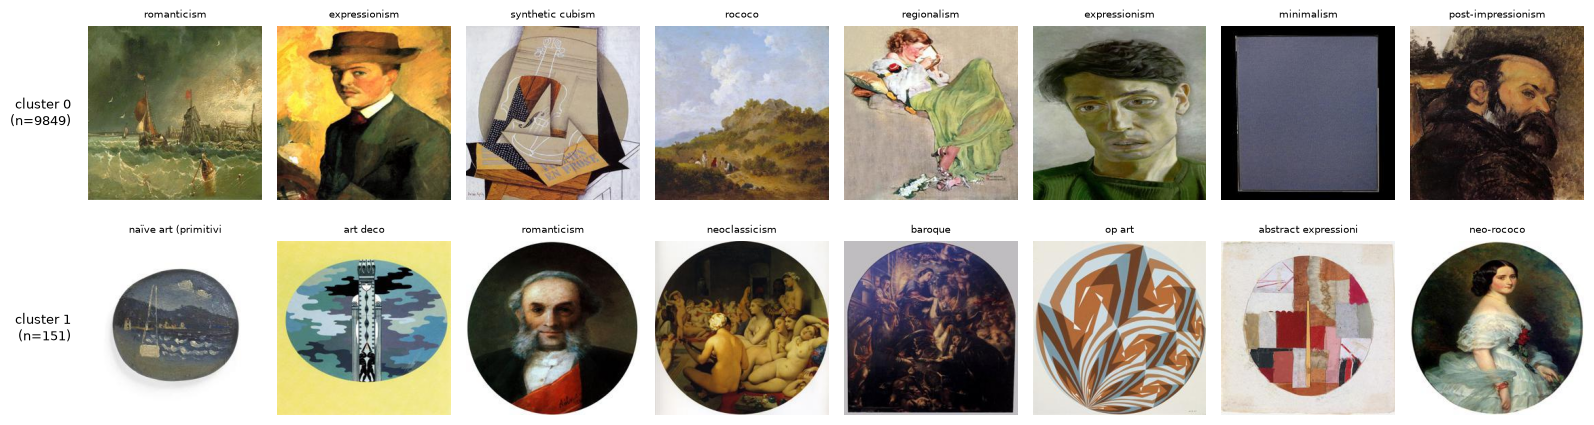

In [ ]:
plot_cluster_samples(ds_cluster, labels, n_per_cluster=8, captions=meta["style"], seed=SEED)